# Report Inspector

## What this notebook does

This notebook loads processed PDF documents (as JSON files produced by the `Docling` pipeline) and shows:
1. A visual map of each detected layout element , e.g., text, tables, figures, footnotes, headers etc.
2. The **text content** of a chosen page in markdown format (figures are omitted)

## Prerequisite

To display the individual page elements, it is necessary to have the processed JSON version (`DoclingDocument`) of the original PDF document.

In [62]:
import pypdfium2 as pdfium
from pathlib import Path
from rich.console import Console
from rich.panel import Panel
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches # for drawing bounding boxes

from docling_core.types.doc.document import DoclingDocument, ContentLayer
from docling_core.transforms.serializer.markdown import MarkdownDocSerializer, MarkdownParams

from transformers import AutoTokenizer

from dotenv import load_dotenv

load_dotenv()

tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-Embedding-0.6B")

In [63]:
PDF_DIR = "../data/reports"
OUTPUT_DIR = "../output/converted"

In [64]:
def load_json_file(report_id) -> DoclingDocument:
    """
    Loads the JSON file for a given company as the parsed `DoclingDocument`.
    
    :param report_id: The name of the report (company name_yyyy) for which to load the `JSON` file.
    :return: A `DoclingDocument` object representing the parsed document.
    """
    company = report_id.split("_")[0]
    json_files = list((Path(OUTPUT_DIR) / company).glob("*.json"))
    if len(json_files) == 0:
        raise FileNotFoundError(f"No JSON file found for company '{company}'")
    json_path = [json_files[i] for i, f in enumerate(json_files) if f.stem == report_id][0]
    doc_dl = DoclingDocument.load_from_json(json_path)

    return doc_dl

In [65]:
def load_pdf_file(report_id) -> pdfium.PdfDocument:
    """
    Loads the PDF file for a given report_id as a pypdfium2 PdfDocument.
    
    :param report_id: The name of the report_id whose PDF file is to be loaded.
    :return: A pypdfium2 PdfDocument object representing the loaded PDF file.
    """
    company = report_id.split("_")[0]
    pdf_files = list((Path(PDF_DIR) / company).glob("*.pdf"))
    if len(pdf_files) == 0:
        raise FileNotFoundError(f"No PDF files found for company '{company}'")
    pdf_path = [pdf_files[i] for i, f in enumerate(pdf_files) if f.stem == report_id][0]
    pdf = pdfium.PdfDocument(pdf_path)

    return pdf

In [66]:
def inspector(report_id, page_no):
    """
    Inspects a given page of a PDF report and shows a visualization of the detected layout elements.
    
    :param report_id: The report_id for which to inspect the page.
    :type report_id: str
    :param page_no: The page number to inspect as originally numbered in the PDF.
    :type page_no: int
    """
    
    COLOURS = {
            "title"          : "#e63946",  # red
            "section_header" : "#2a9d8f",  # teal
            "text"           : "#e63946",  # red
            "list_item"      : "#8338ec",  # purple
            "caption"        : "#fb8500",  # orange
            "footnote"       : "#6d6875",  # mauve
            "page_header"    : "#adb5bd",  # grey
            "page_footer"    : "#adb5bd",  # grey
            "table"          : "#1065aa",  # blue
            "picture"        : "#096935",  # green
        }
    
    pdf = load_pdf_file(report_id)
    doc_dl = load_json_file(report_id)

    serializer = MarkdownDocSerializer(doc=doc_dl,
                                       params=MarkdownParams(
                                           layers={ContentLayer.BODY, ContentLayer.FURNITURE},
                                           pages={page_no},
                                           include_hyperlinks=False,
                                           traverse_pictures=False,
                                           image_placeholder=" ",
                                           ),
                                       )
    md = serializer.serialize().text

    page = pdf[page_no - 1] # pdfium starts at index 0
    image = page.render(scale=2).to_pil() # render at 2x scale

    fig, ax = plt.subplots(figsize=(page.get_width() / 72, page.get_height() / 72), dpi=100)
    ax.imshow(image)
    ax.axis('off')

    # page_content = []
    for item, _ in doc_dl.iterate_items(page_no=page_no, included_content_layers=[ContentLayer.BODY, ContentLayer.FURNITURE]):
        label = item.label
        bbox = [item.prov[0].bbox] if hasattr(item, 'prov') and len(item.prov) > 0 else []
        
        # Scale the bounding box coordinates to match the rendered image size (2x scale)
        x = bbox[0].l * 2
        y = (page.get_height() - bbox[0].t) * 2
        width = (bbox[0].r - bbox[0].l) * 2
        height = (bbox[0].t - bbox[0].b) * 2
        
        color = COLOURS.get(label, "#dddddd")  # default to white

        patch = mpatches.Rectangle(
            (x, y), # x, y coordinates as anchor point (top-left corner)
            width, # width
            height, # height
            linewidth=1,
            edgecolor=color, # border color
            facecolor=color, # transparent fill
            alpha=0.15 # transparency
        )
        ax.add_patch(patch)
        ax.text(x,y, label, fontsize=8, color=color, fontweight='bold')
        
    plt.show()
    
    print(f"TOKENS: {len(tokenizer.encode(md))}\n")
    print("-"*30)
    print(md)

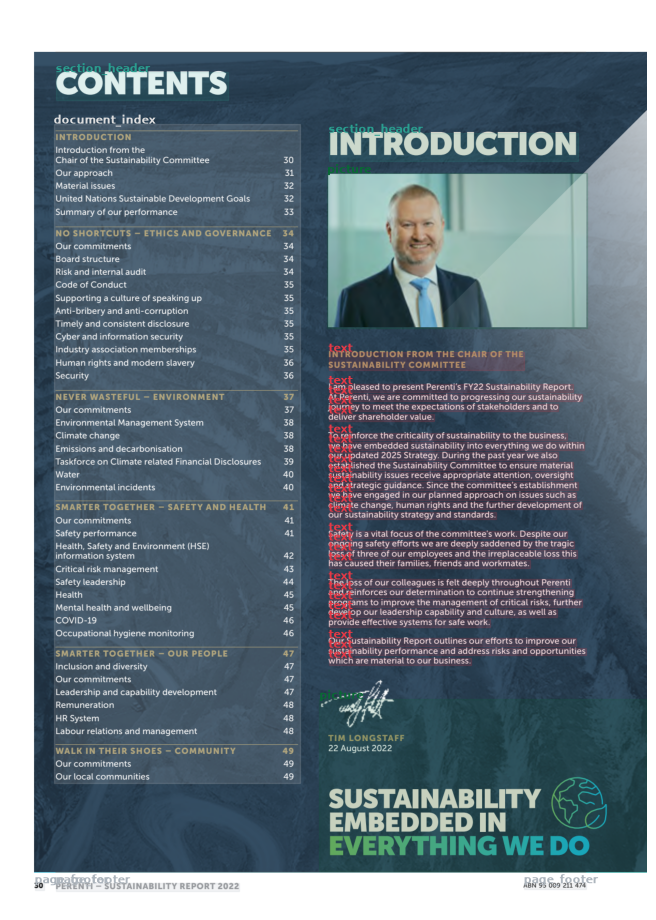

TOKENS: 860

------------------------------
## CONTENTS

| INTRODUCTION Introduction from the Chair of the Sustainability Committee Our approach Material issues United Nations Sustainable Development Goals Summary of our performance                                                                                                                                                                                                                                                                                                                                                          | 30 31 32 32 33                         |
|------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [67]:
inspector("perenti ltd_2022", 32)